The RRF combination and the tuning of its parameters using a training set

Provide: Top 20 Nominee Lists

# Hybrid Retrieval with Reciprocal Rank Fusion

Combine the top-100 rankings from stemmed BM25 and dense E5 retrieval. Tune the RRF parameter only on the development set and later export the final top-20 hybrid candidates.

In [30]:
# Libraries
import json
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1 Load Data

Load and group the development set using the same logic as in notebooks 04 and 05.

In [31]:
# query set
dev = pd.read_csv('../data/clean/test_set_dev.csv')

# Group dev set by unique query so each query has a set of acceptable gold product numbers
dev_queries = dev.groupby('clean_query').agg({
    'gold_product_number': lambda x: set(str(p) for p in x),
    'area_name': 'first',
    'request': 'first'
}).reset_index()
print(f"Development unique queries: {len(dev_queries):,}")
dev_queries.head(3)

Development unique queries: 136


,clean_query,gold_product_number,area_name,request
0,11. akkuruuviväännin – 18 v,{5703550000},Koneet,11. Akkuruuviväännin – 18 V
1,"7. akkuruuviväännin – 10,9 v",{5700130002},Koneet,"7. Akkuruuviväännin – 10,9 V"
2,adblue 10 l,{5861600010},"Tekniset kemikaalit/-tarvikkeet, teipit",Adblue 10 L


Load the saved rankings from the selected keyword and dense retrieval methods.

In [32]:
bm25_stem_rankings = pd.read_csv(
    '../data/clean/bm25_stem_top100_dev.csv',
    dtype={'product_number': str}
)
dense_rankings = pd.read_csv(
    '../data/clean/dense_e5_top100_dev.csv',
    dtype={'product_number': str}
)
print(f"Stemmed BM25 ranking rows: {len(bm25_stem_rankings):,}")
print(f"Dense E5 ranking rows: {len(dense_rankings):,}")

Stemmed BM25 ranking rows: 13,600
Dense E5 ranking rows: 13,600


Verify that both input files contain complete and aligned top-100 rankings for every development query.

In [33]:
# Collect unique queries and check if they match accross the files
dev_query_set = set(dev_queries['clean_query'])
bm25_stem_query_set = set(bm25_stem_rankings['clean_query'])
dense_query_set = set(dense_rankings['clean_query'])
query_sets_match = dev_query_set == bm25_stem_query_set == dense_query_set
print(f"Query sets match: {query_sets_match}")

# Check if stemmed BM25 has 100 products per query
print(f"Stemmed BM25 has 100 products per query: {(bm25_stem_rankings['clean_query'].value_counts() == 100).all()}")

# Check if Dense E5 has 100 products per query
print(f"Dense E5 has 100 products per query: {(dense_rankings['clean_query'].value_counts() == 100).all()}")

Query sets match: True
Stemmed BM25 has 100 products per query: True
Dense E5 has 100 products per query: True


## 2 Evaluation Function

Use the same evaluation function as in notebooks 04 and 05.

In [42]:
# Evaluation function across dev queries
def evaluate_method(method_name, search_func):
    """
    search_func(query_text) -> list of top-10 product numbers.
    Computes Hit@1, Recall@5, Recall@10, MRR, nDCG@5, and Latency.
    """
    t0 = time.time()
    hit1_count = 0
    hit5_count = 0
    hit10_count = 0
    rr_list = []
    ndcg5_list = []
    
    for _, row in dev_queries.iterrows():
        query = row['clean_query']
        gold_set = row['gold_product_number']
        
        # Retrieve top 10
        top_results = search_func(query)
        
        # Hit@1
        if len(top_results) > 0 and top_results[0] in gold_set:
            hit1_count += 1
            
        # Recall@5 & Recall@10
        if any(prod in gold_set for prod in top_results[:5]):
            hit5_count += 1
        if any(prod in gold_set for prod in top_results[:10]):
            hit10_count += 1
            
        # MRR
        rr = 0.0
        for rank, prod in enumerate(top_results[:10], start=1):
            if prod in gold_set:
                rr = 1.0 / rank
                break
        rr_list.append(rr)
        
        # nDCG@5
        dcg = sum(1.0 / np.log2(i + 1) for i, prod in enumerate(top_results[:5], start=1) if prod in gold_set)
        ideal_hits = min(len(gold_set), 5)
        idcg = sum(1.0 / np.log2(i + 1) for i in range(1, ideal_hits + 1))
        ndcg5 = (dcg / idcg) if idcg > 0 else 0.0
        ndcg5_list.append(ndcg5)
        
    elapsed = time.time() - t0
    n = len(dev_queries)
    
    return {
        'Method': method_name,
        'Hit@1': hit1_count / n,
        'Recall@5': hit5_count / n,
        'Recall@10': hit10_count / n,
        'MRR': np.mean(rr_list),
        'nDCG@5': np.mean(ndcg5_list),
        'Latency (ms/query)': (elapsed / n) * 1000
    }

## 3 Hybrid Retrieval with RRF

Prepare function to combine stemmed BM25 and dense E5 rankings for a query using RRF ($1 / (k + rank)$)

In [35]:
# RRF search function
def search_hybrid_rrf(query_text, k=60, top_k=10):
    # Select stemmed BM25 rankings for current query
    bm25_query_rankings = bm25_stem_rankings[bm25_stem_rankings['clean_query'] == query_text]
    # Select dense E5 rankings for current query
    dense_query_rankings = dense_rankings[dense_rankings['clean_query'] == query_text]
    # Store RRF scores by product number
    rrf_scores = {}
    
    # Add product numbers and associated RRF score based on BM25
    for _, row in bm25_query_rankings.iterrows():
        product_number = row['product_number']
        rank = row['rank']
        rrf_scores[product_number] = 1.0 / (k + rank)
        
    # Add dense E5 rank contributions by product numbers
    for _, row in dense_query_rankings.iterrows():
        product_number = row['product_number']
        rank = row['rank']
        rrf_scores[product_number] = rrf_scores.get(product_number, 0.0) + 1.0 / (k + rank)
        
   # Create sorted list of product numbers based on product numbers and scores from dictionary
    ranked_products = sorted(rrf_scores, key=rrf_scores.get, reverse=True)
    # Return
    return ranked_products[:top_k]

Evaluate RRF Parameter k using development set.

In [36]:
# k values to test
rrf_k_values = [20, 40, 60, 80, 100]
rrf_results = []

# Run evaluate method for each k and store results
for k_value in rrf_k_values:
    result = evaluate_method(
        f"Hybrid RRF (k={k_value})",
        lambda query_text: search_hybrid_rrf(query_text, k=k_value, top_k=10)
    )
    rrf_results.append(result)

# Convert results to dataframe and display as table
rrf_results_df = pd.DataFrame(rrf_results)
rrf_results_df.round(4)

,Method,Hit@1,Recall@5,Recall@10,MRR,nDCG@5,Latency (ms/query)
0,Hybrid RRF (k=20),0.2279,0.4118,0.5294,0.3161,0.3278,3.2806
1,Hybrid RRF (k=40),0.2279,0.3971,0.5221,0.3095,0.3178,4.0158
2,Hybrid RRF (k=60),0.2279,0.3824,0.5147,0.3074,0.3118,3.3029
3,Hybrid RRF (k=80),0.2279,0.3824,0.5147,0.3072,0.3118,3.1845
4,Hybrid RRF (k=100),0.2279,0.3824,0.5147,0.3074,0.3118,3.1612


All k parameters yielded identical Hit@1 results. k=20 showed the best results for Recall@5, Recall@10, MRR and nDCG@5. However, improvements of k=20 over the widely established standard value of k=60 and other tested k-values were so minor, that it seems most reasonable to stick to the standard of k=60 to avoid excessive tuning to the development set. Latency was not considered as a criteria, as similar calculations were performed for all tests and differences come down to noise.

Compare RRF with chosen parameter to performance of keyword and dense retrieval only.

In [46]:
# Load prior results
with open('../data/clean/keyword_baseline_results.json', 'r', encoding='utf-8') as f:
    keyword_data = json.load(f)
with open('../data/clean/dense_retrieval_results.json', 'r', encoding='utf-8') as f:
    dense_data = json.load(f)
keyword_df = pd.DataFrame(keyword_data['results'])
dense_df = pd.DataFrame(dense_data['results'])

# Select stemmed BM25, dense E5 and hybrid RRF with k=60
keyword_df = keyword_df[keyword_df['Method'] == 'BM25 (Finnish stemming)']
dense_df = dense_df[dense_df['Method'] == 'Dense (Multilingual-E5-base)']
hybrid_df = rrf_results_df[rrf_results_df['Method'] == 'Hybrid RRF (k=60)']
comparison_df = pd.concat([keyword_df, dense_df, hybrid_df], ignore_index=True)

# Format for clean display
display_cols = ['Method', 'Hit@1', 'Recall@5', 'Recall@10', 'MRR', 'nDCG@5']
comparison_df[display_cols].round({
    'Hit@1': 4, 'Recall@5': 4, 'Recall@10': 4, 'MRR': 4, 'nDCG@5': 4
})

,Method,Hit@1,Recall@5,Recall@10,MRR,nDCG@5
0,BM25 (Finnish stemming),0.1838,0.3529,0.3971,0.2478,0.2661
1,Dense (Multilingual-E5-base),0.1691,0.3162,0.4559,0.2406,0.2436
2,Hybrid RRF (k=60),0.2279,0.3824,0.5147,0.3074,0.3118


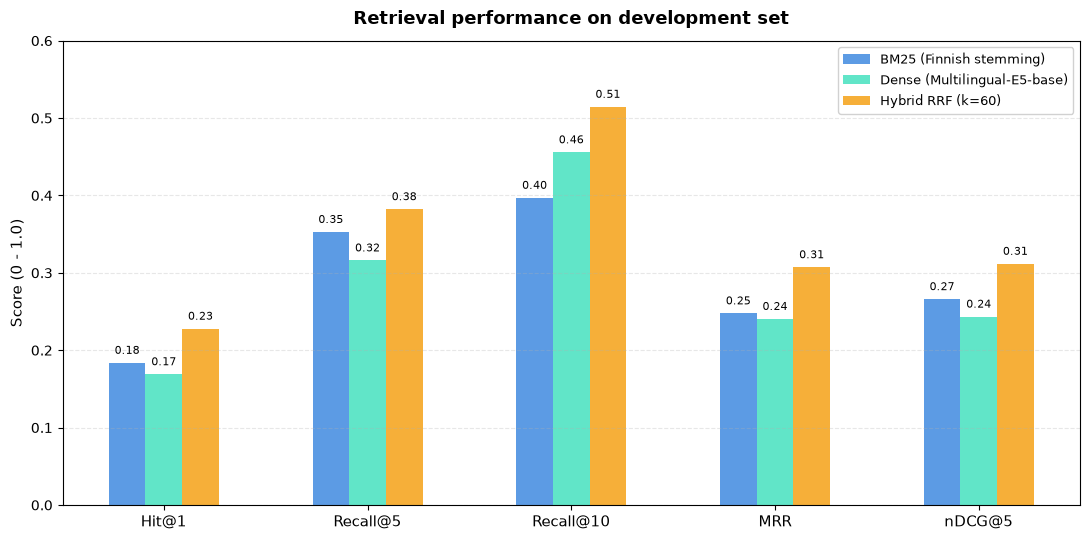

In [39]:
# Plot comparison of retrieval metrics across all methods
metrics = ['Hit@1', 'Recall@5', 'Recall@10', 'MRR', 'nDCG@5']
methods = comparison_df['Method'].tolist()
n_methods = len(methods)

x = np.arange(len(metrics))
width = 0.18

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = ['#4A90E2', '#50E3C2', '#F5A623', '#9013FE']

for i, row in comparison_df.iterrows():
    vals = [row[m] for m in metrics]
    bars = ax.bar(x + (i - (n_methods - 1) / 2) * width, vals, width, label=row['Method'], color=colors[i % len(colors)], alpha=0.9)
    # Add data labels
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.008, f"{h:.2f}", ha='center', va='bottom', fontsize=8, rotation=0)

ax.set_ylabel('Score (0 - 1.0)', fontsize=11)
ax.set_title('Retrieval performance on development set', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 0.6)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

Evaluation by Category

In [41]:
# evaluate query hits per category for selected methods
cat_records = []

# load previous retrieval category records from dense_retrieval_results.json
cat_records.extend(dense_data['top_categories_breakdown'])

# evaluate hybrid RRF by category
for _, row in dev_queries.iterrows():
    top_res = search_hybrid_rrf(row['clean_query'], k=60)
    gold = row['gold_product_number']
    h1 = int(len(top_res) > 0 and top_res[0] in gold)
    r5 = int(any(p in gold for p in top_res[:5]))
    cat_records.append({
        'Method': 'Hybrid RRF (k=60)',
        'area_name': row['area_name'],
        'Hit@1': float(h1),
        'Recall@5': float(r5)
    })

df_cat = pd.DataFrame(cat_records)
selected_category_methods = ['BM25 Stem', 'Dense E5', 'Hybrid RRF (k=60)']
df_cat = df_cat[df_cat['Method'].isin(selected_category_methods)]
top_cats = dev_queries['area_name'].value_counts().head(5).index

# summary tables
cat_table_h1 = df_cat[df_cat['area_name'].isin(top_cats)].groupby(['area_name', 'Method'])['Hit@1'].mean().unstack('Method')
cat_table_r5 = df_cat[df_cat['area_name'].isin(top_cats)].groupby(['area_name', 'Method'])['Recall@5'].mean().unstack('Method')

print("Hit@1 by Category:")
display(cat_table_h1.round(3))

print("\nRecall@5 by Category:")
display(cat_table_r5.round(3))

Hit@1 by Category:


Method,BM25 Stem,Dense E5,Hybrid RRF (k=60)
area_name,,,
Kiinnitystarvikkeet,0.000,0.083,0.083
Käsityökalut,0.258,0.065,0.323
Materiaalin mekaaninen työstö,0.095,0.095,0.143
"Tekniset kemikaalit/-tarvikkeet, teipit",0.143,0.286,0.143
Työturvallisuus,0.143,0.179,0.143



Recall@5 by Category:


Method,BM25 Stem,Dense E5,Hybrid RRF (k=60)
area_name,,,
Kiinnitystarvikkeet,0.083,0.083,0.083
Käsityökalut,0.484,0.387,0.581
Materiaalin mekaaninen työstö,0.286,0.286,0.333
"Tekniset kemikaalit/-tarvikkeet, teipit",0.214,0.429,0.286
Työturvallisuus,0.250,0.214,0.214


**Conclusion**
- Hybrid Retrieval using RRF shows clear overall performance gains over using either keyword or dense search in all metrics.
- Results by categories, however, show a more nuanced picture.
    - Hybrid search performs best across Hit@1 and Recall@5 for hand tools and mechanical processing. Here, hybrid retrieval seems to benefit from both keyword retrievals exact matching as well as dense retrievals semantic understanding.
    - For fastening accessories hybrid search only achieves to match the performance of dense search.
    - In technical chemicals/tapes and safety equipment, hybrid retrieval does not manage to outperform the strongest individual method. Here, combining the results does not seem to improve outcomes.
- However, overall hybrid RRF still yielded the best results.

## Export Hybrid Ranking Top 20
Export hybrid ranking top 20 for the reranking in the following notebooks.

In [47]:
# Store one row for each query and ranked product
hybrid_rrf_top20_records = []
# Generate top-20 using selected RRF configuration
for _, row in dev_queries.iterrows():
    top_results = search_hybrid_rrf(row['clean_query'], k=60, top_k=20)
    for rank, product_number in enumerate(top_results, start=1):
        hybrid_rrf_top20_records.append({
            'clean_query': row['clean_query'],
            'rank': rank,
            'product_number': product_number
        })

# Saving final top 20 as CSV file
hybrid_rrf_top20 = pd.DataFrame(hybrid_rrf_top20_records)
top20_output_path = '../data/clean/hybrid_rrf_top20_dev.csv'
hybrid_rrf_top20.to_csv(top20_output_path, index=False)
print(f"Top-20 hybrid RRF rankings saved to '{top20_output_path}' ({len(hybrid_rrf_top20):,} rows)")

Top-20 hybrid RRF rankings saved to '../data/clean/hybrid_rrf_top20_dev.csv' (2,720 rows)
